In [1]:
# Linear SVM on GSE78220 with 10 repeats of 5-fold cross validation (50 results)
# same amount of results as the logistic regression and random forest runs so the comparison is fair
# compared against a baseline that always predicts the most common class

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

from shared_setup import load_data, get_repeated_folds, evaluate_repeated

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 2)

In [2]:
# load the data -> 27 pretreatment samples (Pt16 left out), 26 patients
# y: 1 = responder (complete/partial response), 0 = non-responder (progressive disease)
X, y, groups, info = load_data()

print("Samples x genes:", X.shape)
print("Responders:", int(y.sum()), " Non-responders:", int((y == 0).sum()))
print("Unique patients:", len(set(groups)))

Samples x genes: (27, 25268)
Responders: 15  Non-responders: 12
Unique patients: 26


In [3]:
# 10 repeats x 5 folds = 50 train/test splits
# folds are made per patient (so Pt27A and Pt27B stay together) and stratified so every fold has both classes
# each repeat shuffles the patients differently (random_state 0 to 9)
# saved in cv_folds_repeated.csv so everyone can use the exact same splits
repeated_folds = get_repeated_folds(info)

n_splits = sum(len(f) for f in repeated_folds.values())
print("Repeats:", len(repeated_folds), " Folds per repeat:", len(repeated_folds[1]), " Total splits:", n_splits)

# check: no patient in both train and test in any split (Pt27A and Pt27B stay together)
# and every sample is tested exactly once in each repeat
for r, folds in repeated_folds.items():
    tested = []
    for tr, te in folds:
        assert not set(groups[tr]) & set(groups[te])
        assert set(y[te]) == {0, 1}   # both responders and non-responders in every test fold
        tested += list(te)
    assert sorted(tested) == list(range(len(y)))
print("OK: patients never split across train/test, both classes in every test fold, every sample tested once per repeat")

Repeats: 10  Folds per repeat: 5  Total splits: 50
OK: patients never split across train/test, both classes in every test fold, every sample tested once per repeat


In [4]:
# SVM pipeline -> every step is fit on the training fold only
svm = Pipeline([
    ("drop_constant", VarianceThreshold(0.0)),   # drop genes that are the same in every training sample
    ("scale", StandardScaler()),                 # put all genes on the same scale
    ("svm", SVC(kernel="linear", C=1.0)),        # linear SVM, fixed C (no tuning yet)
])

# baseline -> always predicts the most common class in the training fold
baseline = DummyClassifier(strategy="most_frequent")

In [5]:
# run all 50 splits for both models (this takes a little while)
svm_res, svm_cm = evaluate_repeated(svm, X, y, repeated_folds, name="Linear SVM")
base_res, base_cm = evaluate_repeated(baseline, X, y, repeated_folds, name="Most-frequent baseline")

results = pd.concat([svm_res, base_res], ignore_index=True)
results.to_csv("svm_results_10x5.csv", index=False)   # 100 rows: 50 SVM + 50 baseline

metrics = ["balanced_accuracy", "roc_auc", "sensitivity", "specificity"]
print("Rows per model:", results.groupby("model").size().to_dict())
results[["model", "repeat", "fold", "n_test"] + metrics + ["TN", "FP", "FN", "TP"]].head(10)

Rows per model: {'Linear SVM': 50, 'Most-frequent baseline': 50}


,model,repeat,fold,n_test,balanced_accuracy,roc_auc,sensitivity,specificity,TN,FP,FN,TP
0,Linear SVM,1,1,6,0.50,0.44,0.33,0.67,2,1,2,1
1,Linear SVM,1,2,5,0.67,0.67,1.00,0.33,1,2,0,2
2,Linear SVM,1,3,5,0.42,0.33,0.33,0.50,1,1,2,1
3,Linear SVM,1,4,5,0.75,0.67,1.00,0.50,1,1,0,3
4,Linear SVM,1,5,6,0.62,0.38,0.75,0.50,1,1,1,3
5,Linear SVM,2,1,6,0.67,0.67,1.00,0.33,1,2,0,3
6,Linear SVM,2,2,5,0.50,0.50,1.00,0.00,0,3,0,2
7,Linear SVM,2,3,5,0.42,0.67,0.33,0.50,1,1,2,1
8,Linear SVM,2,4,6,0.38,0.50,0.75,0.00,0,2,1,3
9,Linear SVM,2,5,5,0.17,0.17,0.33,0.00,0,2,2,1


In [6]:
# summary over all 50 splits -> mean, std, min, max
summary = results.groupby("model")[metrics].agg(["mean", "std", "min", "max"])
summary

balanced_accuracy                   roc_auc        \
                                    mean   std   min   max    mean   std   
model                                                                      
Linear SVM                          0.49  0.17  0.17  0.83    0.46  0.23   
Most-frequent baseline              0.50  0.00  0.50  0.50    0.50  0.00   

                                  sensitivity                 specificity  \
                         min  max        mean   std  min  max        mean   
model                                                                       
Linear SVM              0.11  1.0        0.55  0.26  0.0  1.0        0.44   
Most-frequent baseline  0.50  0.5        1.00  0.00  1.0  1.0        0.00   

                                       
                        std  min  max  
model                                  
Linear SVM              0.3  0.0  1.0  
Most-frequent baseline  0.0  0.0  0.0

In [7]:
# average score for each repeat -> shows how much the result depends on how the patients were shuffled
per_repeat = results.groupby(["model", "repeat"])[metrics].mean().unstack("model")
per_repeat

balanced_accuracy                           roc_auc  \
model         Linear SVM Most-frequent baseline Linear SVM   
repeat                                                       
1                   0.59                    0.5       0.50   
2                   0.42                    0.5       0.50   
3                   0.38                    0.5       0.36   
4                   0.54                    0.5       0.60   
5                   0.56                    0.5       0.56   
6                   0.65                    0.5       0.46   
7                   0.46                    0.5       0.44   
8                   0.42                    0.5       0.33   
9                   0.42                    0.5       0.37   
10                  0.49                    0.5       0.51   

                              sensitivity                        specificity  \
model  Most-frequent baseline  Linear SVM Most-frequent baseline  Linear SVM   
repeat                                                                         
1                         0.5        0.68                    1.0        0.50   
2                         0.5        0.68                    1.0        0.17   
3                         0.5        0.47                    1.0        0.30   
4                         0.5        0.58                    1.0        0.50   
5                         0.5        0.52                    1.0        0.60   
6                         0.5        0.57                    1.0        0.73   
7                         0.5        0.52                    1.0        0.40   
8                         0.5        0.40                    1.0        0.43   
9                         0.5        0.38                    1.0        0.47   
10                        0.5        0.65                    1.0        0.33   

                               
model  Most-frequent baseline  
repeat                         
1                         0.0  
2                         0.0  
3                         0.0  
4                         0.0  
5                         0.0  
6                         0.0  
7                         0.0  
8                         0.0  
9                         0.0  
10                        0.0

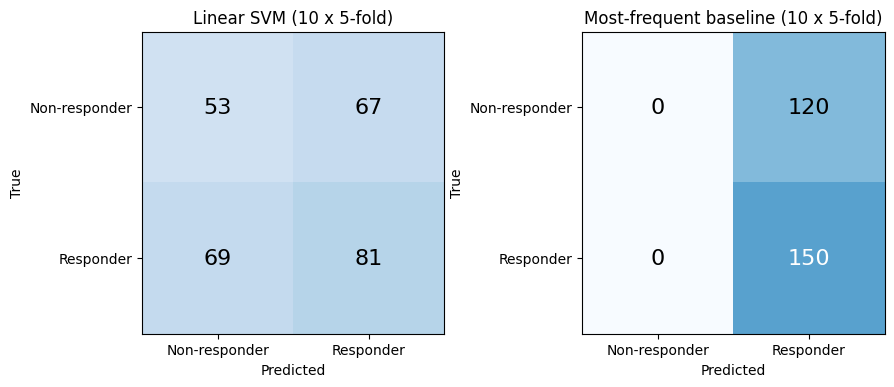

In [8]:
# confusion matrices added up over all 50 splits
# every sample is tested once per repeat -> 27 x 10 = 270 predictions in total
labels = ["Non-responder", "Responder"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (title, cm) in zip(axes, [("Linear SVM", svm_cm), ("Most-frequent baseline", base_cm)]):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.sum() / 2 else "black")
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title + " (10 x 5-fold)")

plt.tight_layout()
plt.show()

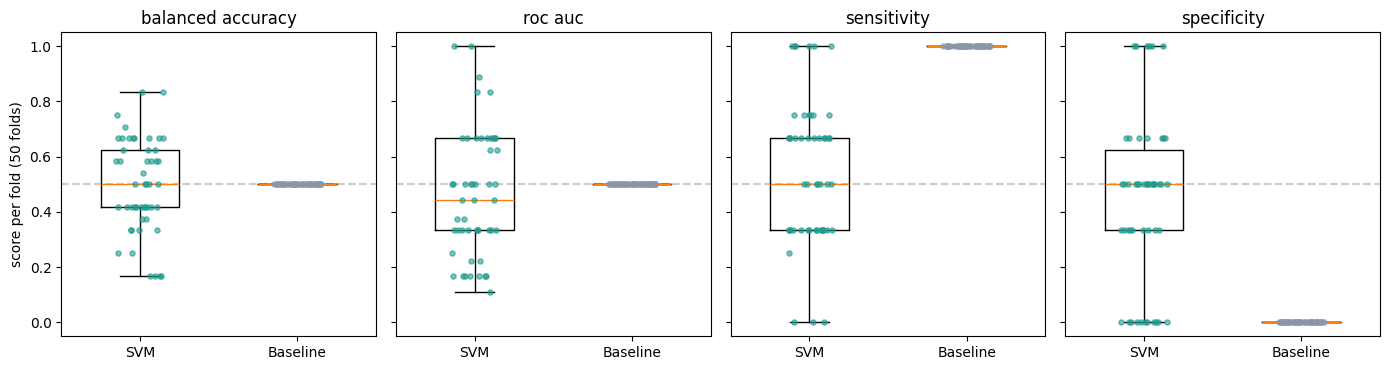

In [9]:
# spread of the 50 fold scores -> box shows the middle half, dots are the individual folds
# dashed line at 0.5 = chance level
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
colors = {"Linear SVM": "#1f9b8f", "Most-frequent baseline": "#8a97a8"}
rng = np.random.default_rng(0)

for ax, m in zip(axes, metrics):
    data = [grp[m].to_numpy() for _, grp in results.groupby("model", sort=False)]
    ax.boxplot(data, widths=0.5, showfliers=False)
    for i, (name, grp) in enumerate(results.groupby("model", sort=False), start=1):
        x = i + rng.uniform(-0.15, 0.15, len(grp))   # jitter so the dots don't sit on top of each other
        ax.scatter(x, grp[m], color=colors[name], s=14, alpha=0.6, zorder=3)
    ax.set_xticks([1, 2], ["SVM", "Baseline"])
    ax.set_title(m.replace("_", " "))
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, color="#cccccc", linestyle="--", zorder=1)

axes[0].set_ylabel("score per fold (50 folds)")
plt.tight_layout()
plt.show()

In [10]:
# notes:
# - 10 x 5-fold gives 50 results, same as the LR and RF runs
# - fixed C = 1.0 and all genes, tuning / feature selection after the professor confirms the setup
# - for a fully fair comparison all three models should use the splits in cv_folds_repeated.csv
print(summary.loc["Linear SVM"].xs("mean", level=1).round(3))

balanced_accuracy    0.49
roc_auc              0.46
sensitivity          0.55
specificity          0.44
Name: Linear SVM, dtype: float64
